Cell 1 – Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

Cell 2 – Load the dataset

In [3]:
df = pd.read_csv("uber.csv")

print("First 5 records:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

First 5 records:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

Cell 3 – Data preprocessing

In [4]:
# Remove unnecessary columns
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

# Remove missing values
df.dropna(inplace=True)

# Remove invalid fare amounts
df = df[df["fare_amount"] > 0]

# Remove invalid geographical coordinates
df = df[
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42)
]

# Remove invalid passenger counts
df = df[df["passenger_count"].between(1, 6)]

# Extract date and time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.dayofweek

print("Dataset after preprocessing:")
print(df.head())

print("\nShape:", df.shape)

Dataset after preprocessing:
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2         -73.962565         40.772647                1    21   24      8   
3         -73.965316         40.803349                3     8   26      6   
4         -73.973082         40.761247                5    17   28      8   

   weekday  
0        3  
1      

Cell 4 – Calculate distance using Haversine formula

In [5]:
# Convert coordinates into radians
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])

lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

# Calculate differences
dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine formula
a = (
    np.sin(dlat / 2)**2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2)**2
)

# Calculate distance in kilometers
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

# Remove zero-distance trips
df = df[df["distance_km"] > 0].copy()

print(df[["distance_km", "fare_amount"]].head())

   distance_km  fare_amount
0     1.683323          7.5
1     2.457590          7.7
2     5.036377         12.9
3     1.661683          5.3
4     4.475450         16.0


Cell 5 – Identify outliers using IQR method

In [6]:
# Calculate IQR for fare amount
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Number of outliers:", len(outliers))

print("Lower Bound:", lower)
print("Upper Bound:", upper)

Number of outliers: 16517
Lower Bound: -3.75
Upper Bound: 22.25


Cell 6 – Visualize outliers using boxplot

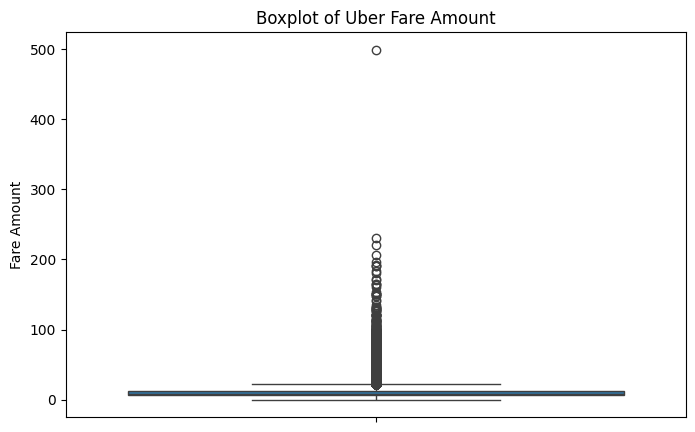

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["fare_amount"])

plt.title("Boxplot of Uber Fare Amount")
plt.ylabel("Fare Amount")

plt.show()

Cell 7 – Remove outliers

In [8]:
# Remove fare outliers
df = df[
    df["fare_amount"].between(lower, upper)
].copy()

# Calculate IQR for distance
Q1 = df["distance_km"].quantile(0.25)
Q3 = df["distance_km"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Remove distance outliers
df = df[
    df["distance_km"].between(lower, upper)
].copy()

print("Dataset after removing outliers:")
print(df.shape)

Dataset after removing outliers:
(168801, 12)


Cell 8 – Correlation analysis

Correlation with Fare Amount:
fare_amount          1.000000
distance_km          0.795088
dropoff_longitude    0.034008
month                0.032705
passenger_count      0.016832
weekday              0.013102
hour                 0.006843
day                  0.004878
pickup_longitude    -0.015299
pickup_latitude     -0.078051
dropoff_latitude    -0.109348
Name: fare_amount, dtype: float64


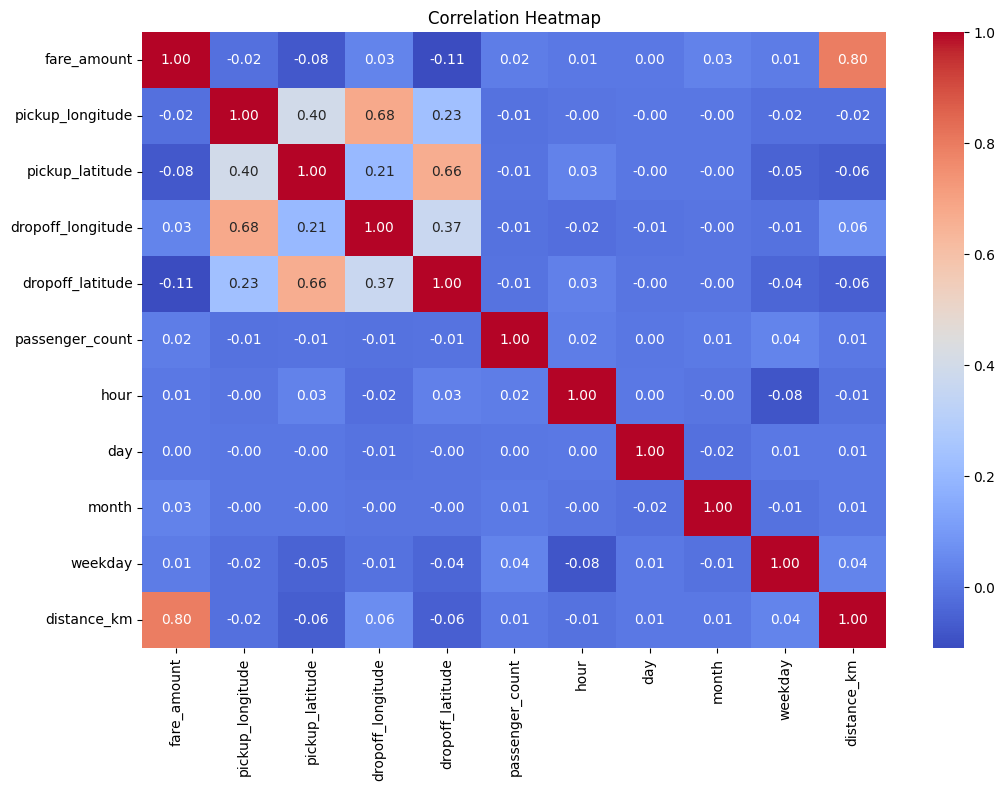

In [9]:
# Calculate correlation
corr = df.select_dtypes(include=np.number).corr()

print("Correlation with Fare Amount:")
print(corr["fare_amount"].sort_values(ascending=False))

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Cell 9 – Separate independent and dependent variables

In [10]:
# Independent variables
X = df[
    [
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude",
        "passenger_count",
        "hour",
        "day",
        "month",
        "weekday",
        "distance_km"
    ]
]

# Dependent variable
y = df["fare_amount"]

print("Independent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())

Independent Variables:
   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  hour  day  month  weekday  distance_km  
0                1    19    7      5        3     1.683323  
1                1    20   17      7        4     2.457590  
2                1    21   24      8        0     5.036377  
3                3     8   26      6        4     1.661683  
4                5    17   28      8        3     4.475450  

Dependent Variable:
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


Cell 10 – Split dataset into training and testing sets

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (135040, 10)
Testing Data: (33761, 10)


Cell 11 – Implement Linear Regression

In [12]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict fare prices
lr_pred = lr_model.predict(X_test)

print("Linear Regression Model Implemented Successfully!")

Linear Regression Model Implemented Successfully!


Cell 12 – Implement Random Forest Regression

In [13]:
# Create model
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict fare prices
rf_pred = rf_model.predict(X_test)

print("Random Forest Regression Model Implemented Successfully!")

Random Forest Regression Model Implemented Successfully!


Cell 13 – Evaluate Linear Regression

In [14]:
lr_r2 = r2_score(y_test, lr_pred)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_pred)
)

lr_mae = mean_absolute_error(y_test, lr_pred)

print("Linear Regression Results")

print("R2 Score:", lr_r2)
print("RMSE:", lr_rmse)
print("MAE:", lr_mae)

Linear Regression Results
R2 Score: 0.6370427197623836
RMSE: 2.2300746101855533
MAE: 1.5988019473714394


Cell 14 – Evaluate Random Forest Regression

In [15]:
rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_mae = mean_absolute_error(y_test, rf_pred)

print("Random Forest Regression Results")

print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)

Random Forest Regression Results
R2 Score: 0.697914254670203
RMSE: 2.034495593110363
MAE: 1.436154241082443


Cell 15 – Compare both models

In [16]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [lr_r2, rf_r2],
    "RMSE": [lr_rmse, rf_rmse],
    "MAE": [lr_mae, rf_mae]
})

print("Model Comparison:")
print(results)

# Find best model
best_model = results.loc[
    results["R2 Score"].idxmax(), "Model"
]

print("\nBest Performing Model:", best_model)

Model Comparison:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.637043  2.230075  1.598802
1      Random Forest  0.697914  2.034496  1.436154

Best Performing Model: Random Forest


Cell 16 – Visualize model comparison

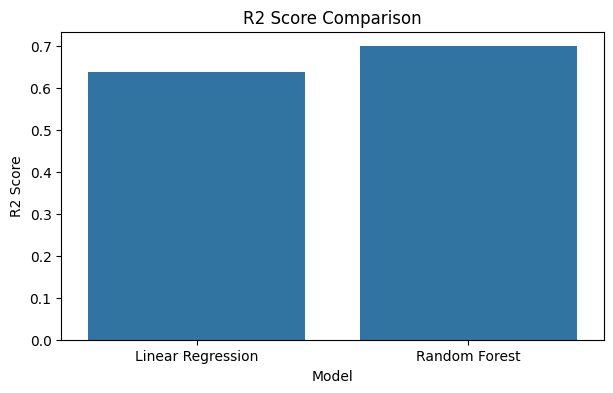

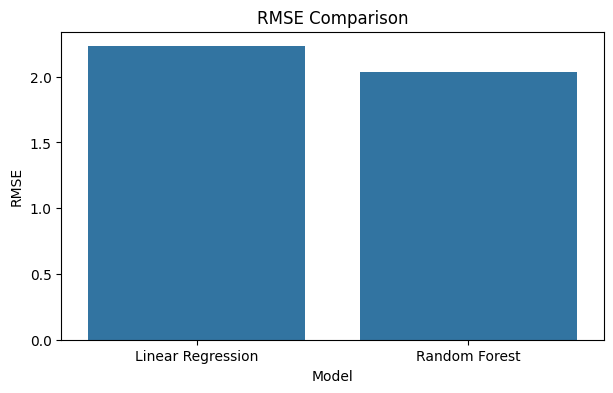

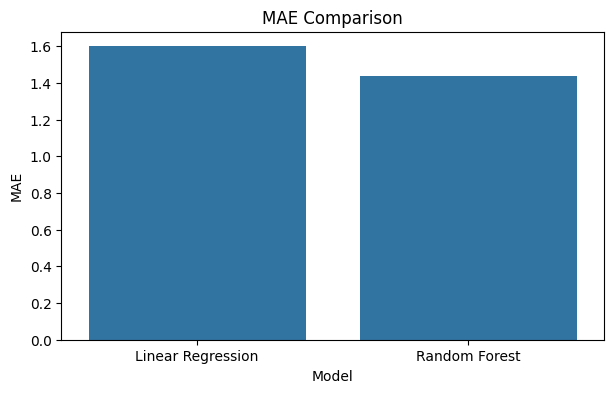

In [17]:
# R2 Score comparison
plt.figure(figsize=(7, 4))

sns.barplot(data=results, x="Model", y="R2 Score")

plt.title("R2 Score Comparison")
plt.show()


# RMSE comparison
plt.figure(figsize=(7, 4))

sns.barplot(data=results, x="Model", y="RMSE")

plt.title("RMSE Comparison")
plt.show()


# MAE comparison
plt.figure(figsize=(7, 4))

sns.barplot(data=results, x="Model", y="MAE")

plt.title("MAE Comparison")
plt.show()

Cell 17 – Predict fare for a sample ride (optional)

In [18]:
# Sample ride details
sample = pd.DataFrame([{
    "pickup_longitude": -73.985,
    "pickup_latitude": 40.748,
    "dropoff_longitude": -73.985,
    "dropoff_latitude": 40.758,
    "passenger_count": 2,
    "hour": 10,
    "day": 15,
    "month": 5,
    "weekday": 2,
    "distance_km": 1.5
}])

# Predict using Random Forest
predicted_fare = rf_model.predict(sample)

print("Predicted Uber Fare: $", round(predicted_fare[0], 2))

Predicted Uber Fare: $ 8.15
